In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

In [3]:
df = pd.read_csv("/kaggle/input/datasets/farazmirza01/loan-dataset/loan.csv")

In [4]:
file_path = '/kaggle/input/datasets/farazmirza01/loan-dataset/loan.csv' 

if not os.path.exists(file_path):
    print(f"Error: '{file_path}' not found. Please upload the file or check the path.")
else:
    df = pd.read_csv(file_path)
    print("--- Dataset Summary ---")
    print(df.info())
    print("\n--- First 5 Rows of Data ---")
    print(df.head())

--- Dataset Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Income       30 non-null     int64 
 1   Loan Amount  30 non-null     int64 
 2   Default      30 non-null     object
dtypes: int64(2), object(1)
memory usage: 852.0+ bytes
None

--- First 5 Rows of Data ---
   Income  Loan Amount Default
0      15            8      No
1      30            8      No
2       5            9     Yes
3      22           10      No
4      33           12      No



Generating Scatter Plot...


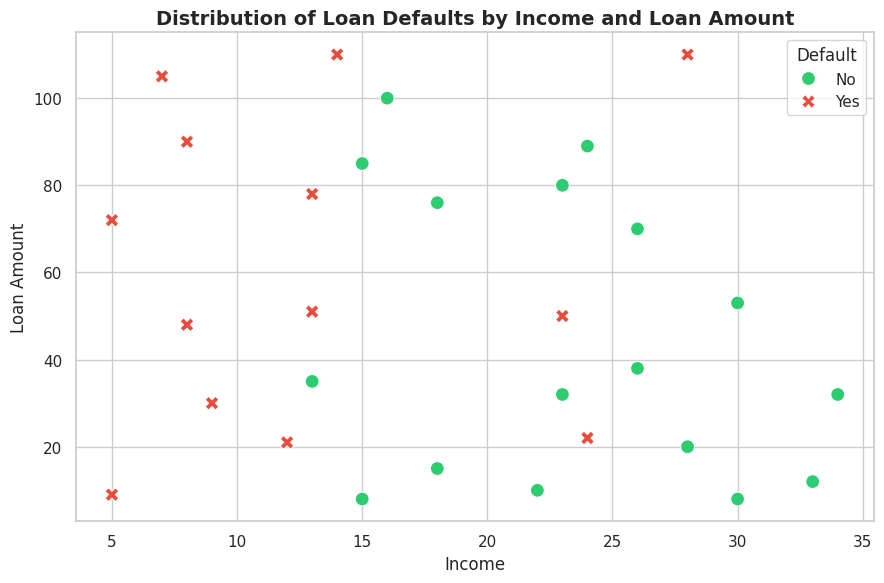

In [5]:
print("\nGenerating Scatter Plot...")
plt.figure(figsize=(9, 6))
sns.scatterplot(
data=df, 
x='Income', 
y='Loan Amount', 
hue='Default', 
style='Default', 
s=100, 
palette={'No': '#2ecc71', 'Yes': '#e74c3c'}
)
plt.title('Distribution of Loan Defaults by Income and Loan Amount', fontsize=14, fontweight='bold')
plt.xlabel('Income', fontsize=12)
plt.ylabel('Loan Amount', fontsize=12)
plt.tight_layout()
plt.show()

In [6]:
X = df[['Income', 'Loan Amount']]
y_raw = df['Default']
    
# Encode categorical target label ('No' -> 0, 'Yes' -> 1)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
    
print("\nClass Mapping:")
for index, class_label in enumerate(label_encoder.classes_):
    print(f"  Class {index}: {class_label}")


Class Mapping:
  Class 0: No
  Class 1: Yes



Training Pruned Decision Tree (Max Depth = 3)...
Pruned Tree Training Accuracy: 0.9333

Pruned Tree Classification Report:
              precision    recall  f1-score   support

          No       0.89      1.00      0.94        17
         Yes       1.00      0.85      0.92        13

    accuracy                           0.93        30
   macro avg       0.95      0.92      0.93        30
weighted avg       0.94      0.93      0.93        30


Pruned Tree Confusion Matrix:


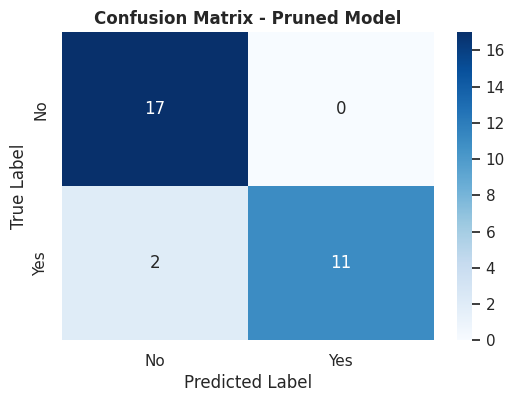

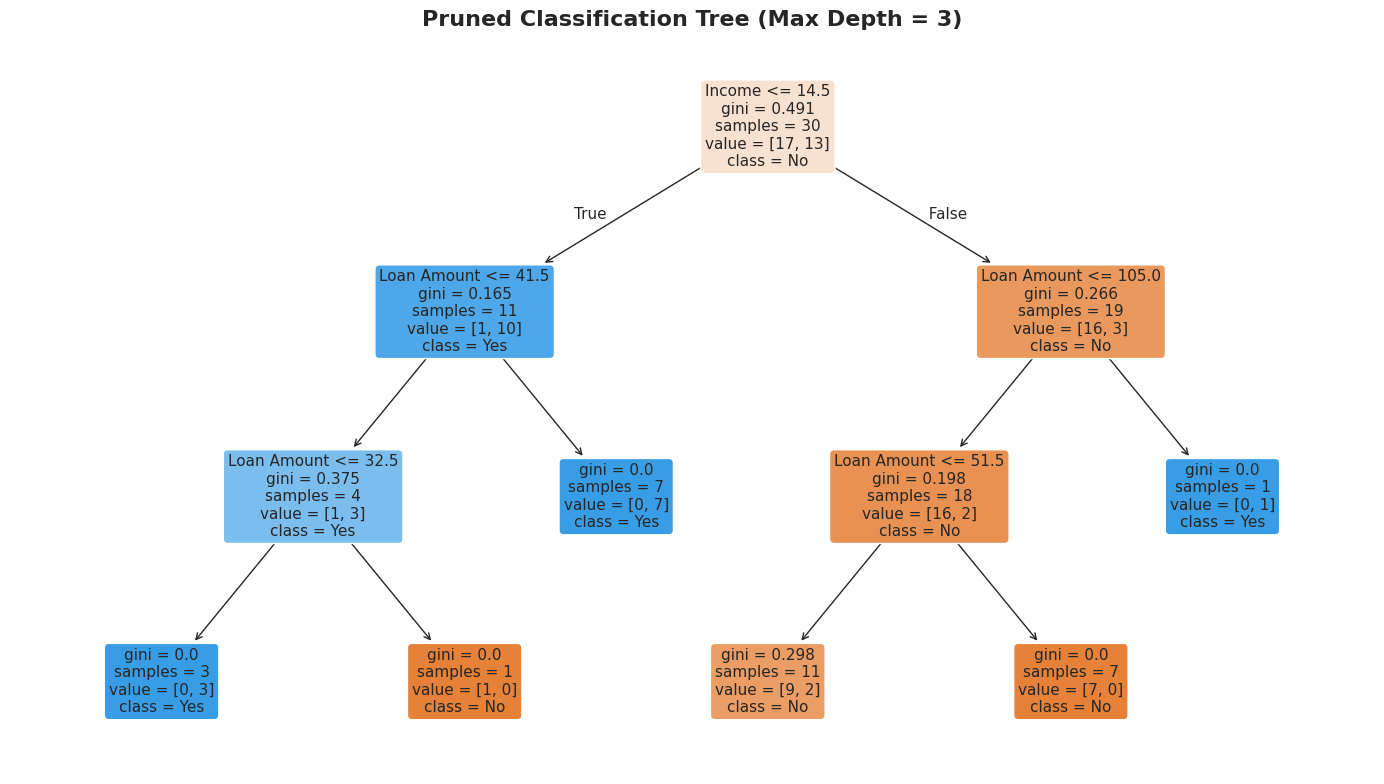

In [7]:
print("\nTraining Pruned Decision Tree (Max Depth = 3)...")
clf_pruned = DecisionTreeClassifier(max_depth=3, random_state=42)
clf_pruned.fit(X, y)

# Evaluate Pruned Tree
y_pred_pruned = clf_pruned.predict(X)
pruned_acc = accuracy_score(y, y_pred_pruned)
print(f"Pruned Tree Training Accuracy: {pruned_acc:.4f}")
print("\nPruned Tree Classification Report:")
print(classification_report(y, y_pred_pruned, target_names=label_encoder.classes_))
    
# Confusion Matrix for Pruned Tree
print("\nPruned Tree Confusion Matrix:")
cm = confusion_matrix(y, y_pred_pruned)
plt.figure(figsize=(6, 4))
sns.heatmap(
cm, 
annot=True, 
fmt='d', 
cmap='Blues', 
xticklabels=label_encoder.classes_, 
yticklabels=label_encoder.classes_
)
plt.title('Confusion Matrix - Pruned Model', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Plot Pruned Tree
plt.figure(figsize=(14, 8))
plot_tree(
clf_pruned, 
feature_names=list(X.columns), 
class_names=list(label_encoder.classes_), 
filled=True, 
rounded=True, 
fontsize=11
)
plt.title("Pruned Classification Tree (Max Depth = 3)", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [8]:
print("\n--- Feature Importance Breakdown ---")
importances = clf_pruned.feature_importances_
for col, imp in zip(X.columns, importances):
    print(f"  {col}: {imp * 100:.2f}%")
        
print("\n--- Decision Tree Rules (Text Format) ---")
tree_rules = export_text(clf_pruned, feature_names=list(X.columns))
print(tree_rules)


--- Feature Importance Breakdown ---
  Income: 68.60%
  Loan Amount: 31.40%

--- Decision Tree Rules (Text Format) ---
|--- Income <= 14.50
|   |--- Loan Amount <= 41.50
|   |   |--- Loan Amount <= 32.50
|   |   |   |--- class: 1
|   |   |--- Loan Amount >  32.50
|   |   |   |--- class: 0
|   |--- Loan Amount >  41.50
|   |   |--- class: 1
|--- Income >  14.50
|   |--- Loan Amount <= 105.00
|   |   |--- Loan Amount <= 51.50
|   |   |   |--- class: 0
|   |   |--- Loan Amount >  51.50
|   |   |   |--- class: 0
|   |--- Loan Amount >  105.00
|   |   |--- class: 1

